# Python の `list` はどれだけ余分に確保しているか

第4回では，動的配列の容量が尽きたら **2 倍** にする，というモデルで
償却計算量を説明した。$n$ 回の `append` で写す総数が $n$ 程度に収まり，
1 回あたりならして $O(1)$ になる，という話である。

では本物の CPython はどうしているのか。ここで確かめる。

結論を先に書くと **2 倍ではない**。もっと控えめに，約 **9/8 倍**ずつ増やしている。
それでも償却 $O(1)$ であることは変わらない。
変わるのは定数倍と，捨てる領域の量である。

上のセルから順に実行していけばよい。
数値は計算機によって変わるので，自分の環境で出た値を見てほしい。

## 準備

図に日本語を出すための設定である。中身は読み飛ばしてよい。

In [1]:
# 図の準備。手元でも Colab でも動くようにしてある
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager


def japanese_font():
    """日本語が出るフォント名を返す。無ければ入れる（Colab 用）。"""
    for name in ("IPAexGothic", "Noto Sans CJK JP", "IPAPGothic",
                 "Hiragino Sans", "Yu Gothic", "Meiryo"):
        if any(f.name == name for f in font_manager.fontManager.ttflist):
            return name
    import glob
    import subprocess
    subprocess.run("apt-get -qq install -y fonts-ipaexfont-gothic",
                   shell=True, check=False)
    for path in glob.glob("/usr/share/fonts/**/ipaexg.ttf", recursive=True):
        font_manager.fontManager.addfont(path)
    return "IPAexGothic"


matplotlib.rcParams.update({
    "font.family": japanese_font(),
    "font.size": 11,
    "figure.figsize": (6.0, 3.6),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    # 日本語フォントには原則マイナス記号がないため ASCII のハイフンを使う
    "axes.unicode_minus": False,
})

In [2]:
import sys

print(sys.version)

3.12.15 (main, Oct  3 2026, 01:03:07) [Clang 22.1.3 ]


## 容量を見る

`list` は **要素数**（いま入っている個数）と **容量**（確保してある区画の数）を
別々に持つ。Python から直接は見えないが，オブジェクトの大きさから逆算できる。

`sys.getsizeof(a)` が返すのは `list` オブジェクト自身の大きさで，
確保した区画の分を含む（中身のオブジェクトの大きさは含まない）。
区画 1 つは参照 1 本ぶん（64 bit 環境で 8 バイト）である。

In [3]:
EMPTY = sys.getsizeof([])      # 区画 0 個のときの大きさ
PTR = 8                        # 区画 1 つ = 参照 1 本

def capacity(a):
    """list a に確保されている区画の数。"""
    return (sys.getsizeof(a) - EMPTY) // PTR

print("空の list:", EMPTY, "バイト")

a = []
print("要素数  容量")
for i in range(9):
    print(f"{len(a):6d}{capacity(a):6d}")
    a.append(i)

空の list: 56 バイト
要素数  容量
     0     0
     1     4
     2     4
     3     4
     4     4
     5     8
     6     8
     7     8
     8     8


容量は要素数より大きく，階段状に増えている。
途中の `append` は空いている区画に書くだけなので $O(1)$ で済む。

容量が変わった瞬間だけを拾ってみる。

In [4]:
def growth_points(n):
    """append で容量が変わった瞬間の (そのときの要素数, 新しい容量) を集める。"""
    a = []
    cap = capacity(a)
    out = []
    for i in range(n):
        a.append(i)
        c = capacity(a)
        if c != cap:
            out.append((len(a), c))
            cap = c
    return out

pts = growth_points(400)
print(len(pts), "回")
print([n for n, _ in pts])

20 回
[1, 5, 9, 17, 25, 33, 41, 53, 65, 77, 93, 109, 129, 149, 173, 201, 233, 269, 309, 353]


2 倍のモデルなら 1, 2, 3, 5, 9, 17, 33, 65, 129, 257 となるはずだが，
そうなっていない。前の容量との比を見る。

In [5]:
print("要素数   容量   前の容量との比")
prev = None
for n, c in pts:
    ratio = "" if prev is None else f"{c / prev:.4f}"
    print(f"{n:6d}{c:7d}{ratio:>12}")
    prev = c

要素数   容量   前の容量との比
     1      4            
     5      8      2.0000
     9     16      2.0000
    17     24      1.5000
    25     32      1.3333
    33     40      1.2500
    41     52      1.3000
    53     64      1.2308
    65     76      1.1875
    77     92      1.2105
    93    108      1.1739
   109    128      1.1852
   129    148      1.1562
   149    172      1.1622
   173    200      1.1628
   201    232      1.1600
   233    268      1.1552
   269    308      1.1493
   309    352      1.1429
   353    400      1.1364


比は 2 ではなく **1.125 = 9/8** に近づいている。

配布文書で 2 倍としたのは説明のためのモデルであって，
CPython が実際に使っている係数ではない。
ただし「**定数倍で増やす**」という肝心の点は同じである。

## CPython の式を当ててみる

CPython の `Objects/listobject.c` にある `list_resize` は，
新しい容量を次の式で決めている。

```c
new_allocated = ((size_t)newsize + (newsize >> 3) + 6) & ~(size_t)3;
```

`newsize >> 3` は $\lfloor newsize / 8 \rfloor$ である。つまり

$$
\text{容量} = \left\lfloor \frac{\;newsize + \lfloor newsize/8 \rfloor + 6\;}{4} \right\rfloor \times 4
$$

で，`+ 6` と「4 の倍数に切り下げる」のは小さいときの調整である。
$newsize$ が大きければ $9/8$ 倍に近づく。

In [6]:
def predicted(newsize):
    """CPython の list_resize が確保する区画数。"""
    return (newsize + (newsize >> 3) + 6) & ~3

for n, c in pts[:8]:
    print(f"要素数 {n:4d}   実測 {c:4d}   式 {predicted(n):4d}")

要素数    1   実測    4   式    4
要素数    5   実測    8   式    8
要素数    9   実測   16   式   16
要素数   17   実測   24   式   24
要素数   25   実測   32   式   32
要素数   33   実測   40   式   40
要素数   41   実測   52   式   52
要素数   53   実測   64   式   64


一致している。範囲を広げて全点で確かめる。

In [7]:
pts_all = growth_points(300_000)
mismatch = [(n, c, predicted(n)) for n, c in pts_all if predicted(n) != c]

print(f"確認した点: {len(pts_all)}")
print(f"食い違い:   {len(mismatch)}")
print(f"最後の比:   {pts_all[-1][1] / pts_all[-2][1]:.5f}")

確認した点: 76
食い違い:   0
最後の比:   1.12502


30 万要素まで，容量が変わった **全点**で式と一致した。

## 図にする

容量と要素数を並べて描く。2 倍のモデルも重ねる。

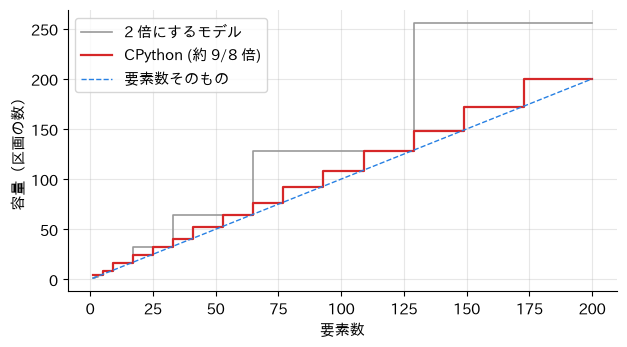

In [8]:
def double_capacity(newsize):
    """配布文書のモデル。容量が尽きるたびに 2 倍にする。"""
    cap = 1
    while cap < newsize:
        cap *= 2
    return cap

def capacity_curve(nmax, grow):
    """要素数 1..nmax のそれぞれに対する容量。"""
    caps, cap = [], 0
    for size in range(1, nmax + 1):
        if size > cap:
            cap = grow(size)
        caps.append(cap)
    return caps

NMAX = 200
xs = range(1, NMAX + 1)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.step(xs, capacity_curve(NMAX, double_capacity), where="post",
        label="2 倍にするモデル", color="#999999", lw=1.2)
ax.step(xs, capacity_curve(NMAX, predicted), where="post",
        label="CPython (約 9/8 倍)", color="#d62728", lw=1.6)
ax.plot(xs, xs, label="要素数そのもの", color="#2780e3", lw=1.0, ls="--")
ax.set_xlabel("要素数")
ax.set_ylabel("容量（区画の数）")
ax.legend()
fig.tight_layout()

2 倍のモデルは，直前に容量を増やしたところで要素数の 2 倍まで跳ね上がる。
CPython の線は要素数のすぐ上を走っている。

**捨てている領域が少ない**ということである。どれくらい違うか数える。

In [9]:
def max_waste(nmax, grow, lo=1):
    """要素数が lo 以上の範囲で、使っていない区画の割合の最大値。"""
    caps = capacity_curve(nmax, grow)
    return max((caps[s - 1] - s) / s for s in range(lo, nmax + 1))

print("要素数が     2 倍のモデル    CPython")
for lo in (1, 10, 100, 1000):
    d = max_waste(100_000, double_capacity, lo)
    c = max_waste(100_000, predicted, lo)
    print(f"{lo:5d} 以上{d:13.1%}{c:11.1%}")

要素数が     2 倍のモデル    CPython
    1 以上       100.0%     300.0%


   10 以上       100.0%      60.0%
  100 以上       100.0%      17.4%
 1000 以上       100.0%      13.0%


2 倍のモデルは，要素数がいくら大きくなっても **100%**，
つまり確保した区画の半分が未使用になる瞬間がある。

CPython は要素数が増えるほど **12.5%**（$= 1/8$）に近づく。
要素数が小さいうちに 300% などと出るのは，式の `+ 6` が効いているためで，
区画 6 個ぶんの話にすぎない。

## どちらも償却 $O(1)$

増やし方が違っても，$n$ 回の `append` で写す要素の総数は
どちらも $n$ の定数倍に収まる。数えてみる。

In [10]:
def total_copied(n, grow):
    """n 回 append したときの (写した要素の総数, 容量を増やした回数)。"""
    cap, total, times = 0, 0, 0
    for size in range(1, n + 1):
        if size > cap:
            total += size - 1      # いま入っている分を新しい領域へ写す
            cap = grow(size)
            times += 1
    return total, times

N = 200_000
print(f"n = {N:,}\n")
print("                 増やした回数      写した総数    n あたり   1 回あたりの操作")
for name, grow in [("2 倍のモデル", double_capacity), ("CPython", predicted)]:
    copied, times = total_copied(N, grow)
    print(f"{name:14s}{times:10d}{copied:16,d}{copied / N:11.2f}{(N + copied) / N:17.2f}")

n = 200,000

                 増やした回数      写した総数    n あたり   1 回あたりの操作
2 倍のモデル               19         262,143       1.31             2.31
CPython               72       1,620,992       8.10             9.10


どちらも「$n$ あたり」の欄が定数に落ち着いている。これが償却 $O(1)$ である。

理屈のうえでは，容量を $r$ 倍ずつ増やすとき写す総数は

$$
1 + r + r^2 + \cdots \;\approx\; \frac{n}{r - 1}
$$

となる。$r = 2$ なら $n$，$r = 9/8$ なら $8n$ である。実測とよく合っている。

$r$ を 1 に近づけるほど，捨てる領域は減るが写す回数は増える。
**時間と領域の交換**がここにも現れている。
CPython は領域のほうを重く見て $9/8$ を選んでいる。

## 課題 W04 問 5 とのつながり

課題では「**毎回 100 区画ずつ**増やす」場合を考えた。
これは定数倍ではないので，$r$ が 1 に近づき続ける。確かめる。

In [11]:
def fixed_capacity(step):
    def grow(newsize):
        return -(-newsize // step) * step      # step の倍数に切り上げる
    return grow

print("     n      写した総数    n あたり")
for n in (1_000, 10_000, 100_000):
    copied, _ = total_copied(n, fixed_capacity(100))
    print(f"{n:7,d}{copied:16,d}{copied / n:11.1f}")

     n      写した総数    n あたり
  1,000           4,500        4.5
 10,000         495,000       49.5
100,000      49,950,000      499.5


「$n$ あたり」が定数にならず，$n$ に比例して増えている。
$n$ を 10 倍すると約 10 倍になっているので，総数は $n^2$ のオーダーである。
1 回あたりならしても $O(n)$ で，**償却しても $O(1)$ にならない**。

定数を大きくしても解決しない。
次のセルで 100 ずつと 10000 ずつを比べると，$n = 200{,}000$ では 100 倍の差が出る。
しかしこれは定数倍の差でしかなく，**増やす回数が $n$ に比例する**ことは変わらない。
$n$ を 10 倍すれば，10000 ずつのほうも増やす回数が 10 倍になる。

In [12]:
for step in (100, 10_000):
    copied, times = total_copied(200_000, fixed_capacity(step))
    print(f"{step:6,d} ずつ : 増やした回数 {times:5d}   写した総数 {copied:14,d}")

   100 ずつ : 増やした回数  2000   写した総数    199,900,000
10,000 ずつ : 増やした回数    20   写した総数      1,900,000


効いているのは「大きく増やすこと」ではなく，
**増やす回数を $n$ に比例させないこと**である。
そのためには増やす量を現在の容量に比例させる，つまり定数倍にするしかない。

## おまけ：時間を測るときの落とし穴

第1回では `a + b` の実行時間を測って，桁数との関係を目で見た。
同じことを `append` でやるとどうなるか。

In [13]:
import time
import statistics

def measure(n=20_000):
    """n 回 append して、1 回ごとの所要時間（ナノ秒）を返す。"""
    a = []
    out = []
    for i in range(n):
        t0 = time.perf_counter_ns()
        a.append(i)
        out.append(time.perf_counter_ns() - t0)
    return out

N = 20_000
elapsed = measure(N)

# i 回目の append のあとの要素数は i + 1
grew = {n for n, _ in growth_points(N)}
spike = [t for i, t in enumerate(elapsed) if i + 1 in grew]
plain = [t for i, t in enumerate(elapsed) if i + 1 not in grew]

print("                  回数     中央値       最大")
print(f"容量を増やした回{len(spike):8d}{statistics.median(spike):9.0f} ns{max(spike):9d} ns")
print(f"それ以外        {len(plain):8d}{statistics.median(plain):9.0f} ns{max(plain):9d} ns")

                  回数     中央値       最大
容量を増やした回      53      263 ns     9085 ns
それ以外           19947       85 ns    25510 ns


**中央値では差が出ている。**容量を増やす回は 2 倍以上かかっている。

**最大値のほうは当てにならない。**
容量と関係のない `append` にも，OS が別の処理に切り替えたなどの理由で
桁違いに遅いものが紛れ込む。1 回が約 100 ns しかないので，
割り込みが 1 回入るだけで順位がひっくり返る。

同じ測定を 5 回くり返すと，何が安定していて何がしていないかが分かる。

In [14]:
print("       中央値（増やした回 / それ以外）   遅い順 12 回中   最大が出たのは")
for run in range(5):
    el = measure(N)
    g = [t for i, t in enumerate(el) if i + 1 in grew]
    o = [t for i, t in enumerate(el) if i + 1 not in grew]
    slowest = sorted(range(N), key=lambda i: el[i], reverse=True)[:12]
    hit = sum(1 for i in slowest if i + 1 in grew)
    which = "増やした回" if max(g) > max(o) else "それ以外"
    print(f"{run + 1} 回目{statistics.median(g):10.0f} ns /{statistics.median(o):7.0f} ns"
          f"{hit:14d} / 12      {which}")

print(f"\n（容量を増やした回は全体で {len(grew)} 回 / {N:,} 回 = {len(grew) / N:.1%}）")

       中央値（増やした回 / それ以外）   遅い順 12 回中   最大が出たのは
1 回目       242 ns /     85 ns            11 / 12      増やした回
2 回目       217 ns /     85 ns            10 / 12      それ以外
3 回目       205 ns /     85 ns            11 / 12      増やした回
4 回目       233 ns /     85 ns             9 / 12      それ以外
5 回目       249 ns /     85 ns             9 / 12      それ以外

（容量を増やした回は全体で 53 回 / 20,000 回 = 0.3%）


安定して出るのは **中央値の差だけ**である。

最大値は容量の増加を指していない。
容量と関係のない回のほうが遅いことが多く，どちらに出るかは実行しだいで変わる。
遅い順 12 回の内訳も実行のたびに揺れる。

第1回の加算は，桁数を増やせばいくらでも重くできたので 1 点ずつ追えた。
ここでは 1 回が短すぎて，同じやり方は通じない。

教訓は 2 つある。

- 時間で確かめるなら，**外れ値ではなく中央値のような頑健な統計量**を見る。
  いちばん遅かった回を拾って原因を決めるのは危うい
- できるなら **時間ではなく回数を数える**。
  このノートの前半でやったように，容量が変わった点を拾って
  写した要素を足し合わせるほうが，計算機の状態に左右されず確実である

## まとめ

- CPython の `list` は容量を **約 9/8 倍**ずつ増やす（2 倍ではない）
- 式は `(n + (n >> 3) + 6) & ~3` で，30 万要素まで全点で一致した
- 9/8 倍でも償却 $O(1)$。写す総数は $n/(r-1) = 8n$ 程度
- 2 倍にくらべて写す手間は増えるが，未使用の区画は最大 100% から 12.5% に減る
- 定数ずつ（100 区画ずつ）増やすと $O(n)$ になる。定数を大きくしても直らない